# Analisis Pengelompokan Provinsi Berdasarkan APM Tahun 2025 Menggunakan K-Means

**Objek:** 38 provinsi di Indonesia  
**Variabel:** APM SD/sederajat, APM SMP/sederajat, dan APM SM/sederajat  
**Metode:** Standardisasi Z-Score dan K-Means  
**Target analisis:** Menghasilkan segmentasi dengan sekurang-kurangnya 4 cluster.

> Catatan metodologis: jumlah cluster tidak boleh dipaksakan dengan mengubah atau membuang nilai provinsi. Notebook ini tetap menggunakan seluruh 38 provinsi. K=2 sampai K=10 dievaluasi untuk transparansi. Karena kebutuhan penelitian menetapkan minimal 4 kelompok, model akhir dipilih dari kandidat K=4 sampai K=10. Hasil evaluasi global tetap dilaporkan, termasuk jika K=2 memperoleh skor lebih baik. Jika cluster beranggotakan satu provinsi, hal tersebut harus disebutkan sebagai cluster tunggal/outlier dan tidak boleh disamarkan.

## 1. Import library

In [ ]:
# Jika diperlukan di Google Colab:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Upload dan membaca dataset

In [ ]:
# Jalankan pada Google Colab. Pilih file CSV APM yang diberikan.
from google.colab import files
uploaded = files.upload()

# Ambil file CSV yang diunggah
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if len(csv_files) == 0:
    raise FileNotFoundError("Tidak ada file CSV yang diunggah.")
if len(csv_files) > 1:
    print("File CSV ditemukan:", csv_files)
file_path = csv_files[0]

# File sumber memiliki beberapa baris judul sebelum header variabel.
# Format sumber: baris ke-1 judul '38 Provinsi', baris ke-2 judul tabel,
# baris ke-3 nama jenjang, baris ke-4 tahun, lalu data provinsi.
raw = pd.read_csv(file_path, header=None)
print("Ukuran file mentah:", raw.shape)
display(raw.head(8))

Saving Dataset - Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan, 2025.csv to Dataset - Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan, 2025 (1).csv
Ukuran file mentah: (40, 4)


,0,1,2,3
0,Provinsi,SD/sederajat,SMP/sederajat,SM/sederajat
1,ACEH,96.32,81.37,70.36
2,SUMATERA UTARA,95.99,77.41,70.4
3,SUMATERA BARAT,97.06,82.7,71.57
4,RIAU,97.54,81.4,65.22
5,JAMBI,97.02,78.47,63.05
6,SUMATERA SELATAN,95.98,74.27,63.08
7,BENGKULU,96.12,78.83,69.32


## 3. Data cleaning dan pembentukan dataset analisis

In [ ]:
# Ambil mulai baris indeks 1: baris pertama data provinsi (karena tidak ada baris judul kosong di atas header)
df = raw.iloc[1:, :4].copy()
df.columns = ["Provinsi", "APM_SD", "APM_SMP", "APM_SM"]

# Bersihkan nama provinsi dan ubah APM menjadi numerik
df["Provinsi"] = df["Provinsi"].astype(str).str.strip().str.upper()
fitur_apm = ["APM_SD", "APM_SMP", "APM_SM"]

for kolom in fitur_apm:
    # Mendukung angka desimal dengan titik atau koma
    df[kolom] = (
        df[kolom].astype(str).str.strip()
        .str.replace(",", ".", regex=False)
    )
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# Hilangkan baris agregat nasional, bukan provinsi
df = df[df["Provinsi"] != "INDONESIA"].copy()

# Hapus baris kosong pada variabel yang digunakan
df = df.dropna(subset=["Provinsi"] + fitur_apm)

# Hilangkan duplikasi nama provinsi jika ada
df = df.drop_duplicates(subset=["Provinsi"], keep="first").reset_index(drop=True)

# Validasi rentang APM (nilai APM seharusnya dalam skala 0-100)
for kolom in fitur_apm:
    if not df[kolom].between(0, 100).all():
        raise ValueError(f"Ditemukan nilai di luar rentang 0-100 pada {kolom}.")

print("Jumlah observasi:", len(df))
print("Jumlah provinsi unik:", df["Provinsi"].nunique())
print("Kolom analisis:", fitur_apm)
display(df)
assert len(df) == 38, "Periksa kembali proses cleaning: target dataset adalah 38 provinsi."

Jumlah observasi: 38
Jumlah provinsi unik: 38
Kolom analisis: ['APM_SD', 'APM_SMP', 'APM_SM']


,Provinsi,APM_SD,APM_SMP,APM_SM
0,ACEH,96.32,81.37,70.36
1,SUMATERA UTARA,95.99,77.41,70.40
2,SUMATERA BARAT,97.06,82.70,71.57
3,RIAU,97.54,81.40,65.22
4,JAMBI,97.02,78.47,63.05
5,SUMATERA SELATAN,95.98,74.27,63.08
6,BENGKULU,96.12,78.83,69.32
7,LAMPUNG,97.64,78.47,67.22
8,KEP. BANGKA BELITUNG,97.00,74.06,65.94
9,KEP. RIAU,98.20,83.55,76.54


## 4. Pemeriksaan kualitas data dan statistik deskriptif

In [ ]:
print("Informasi dataset:")
df.info()

print("\nMissing value:")
display(df.isna().sum().to_frame("Jumlah Missing"))

print("\nDuplikasi:")
print("Duplikasi baris:", df.duplicated().sum())
print("Duplikasi nama provinsi:", df["Provinsi"].duplicated().sum())

print("\nStatistik deskriptif:")
display(df[fitur_apm].describe().T.round(2))

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Provinsi  38 non-null     object 
 1   APM_SD    38 non-null     float64
 2   APM_SMP   38 non-null     float64
 3   APM_SM    38 non-null     float64
dtypes: float64(3), object(1)
memory usage: 1.3+ KB

Missing value:


,Jumlah Missing
Provinsi,0
APM_SD,0
APM_SMP,0
APM_SM,0



Duplikasi:
Duplikasi baris: 0
Duplikasi nama provinsi: 0

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
APM_SD,38.0,95.09,5.49,72.55,95.68,96.39,97.55,98.77
APM_SMP,38.0,77.34,7.46,54.33,75.07,78.47,81.47,88.67
APM_SM,38.0,64.42,9.01,35.59,61.52,65.61,70.24,78.42


## 5. Eksplorasi data

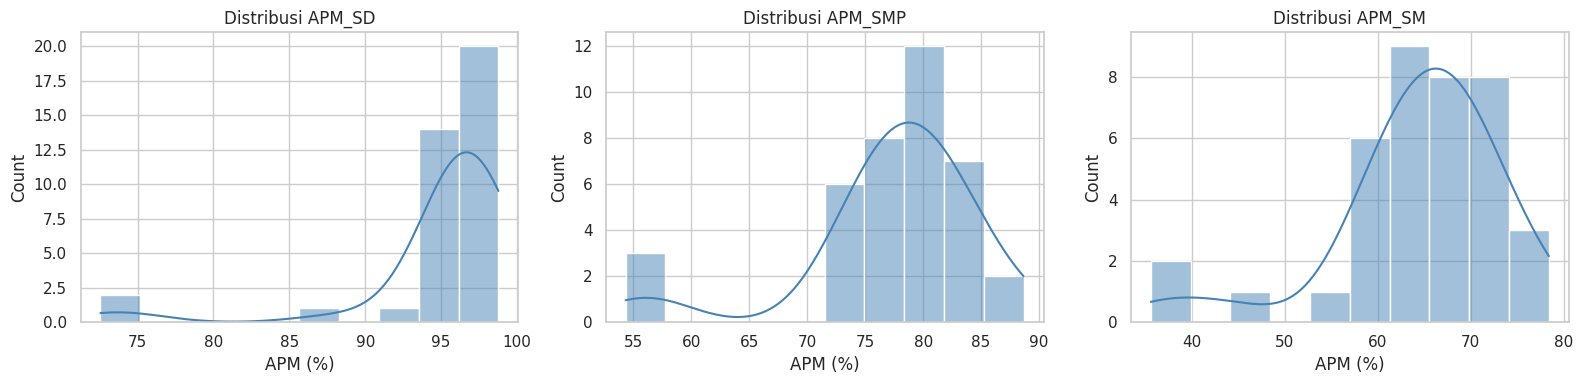

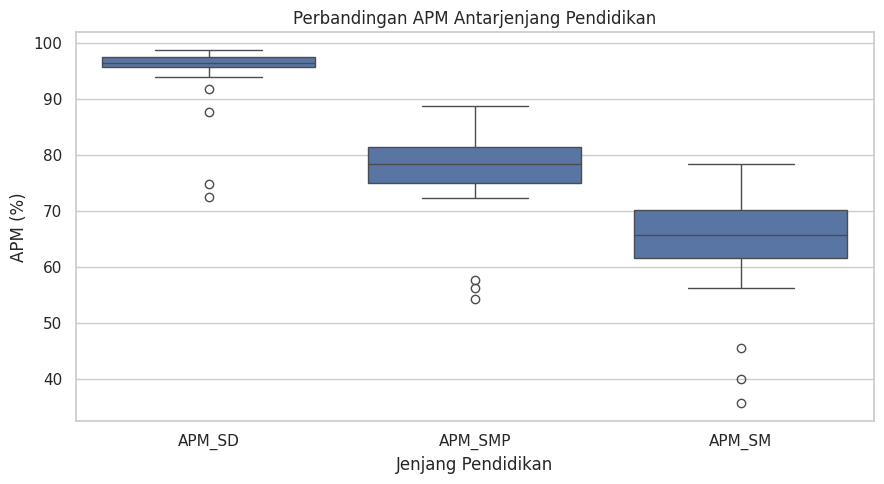

In [ ]:
# Distribusi masing-masing variabel
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kolom in zip(axes, fitur_apm):
    sns.histplot(df[kolom], kde=True, bins=10, ax=ax, color="steelblue")
    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel("APM (%)")
plt.tight_layout()
plt.show()

# Boxplot antarjenjang
df_melt = df.melt(
    id_vars="Provinsi",
    value_vars=fitur_apm,
    var_name="Jenjang Pendidikan",
    value_name="APM"
)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_melt, x="Jenjang Pendidikan", y="APM")
plt.title("Perbandingan APM Antarjenjang Pendidikan")
plt.xlabel("Jenjang Pendidikan")
plt.ylabel("APM (%)")
plt.tight_layout()
plt.show()

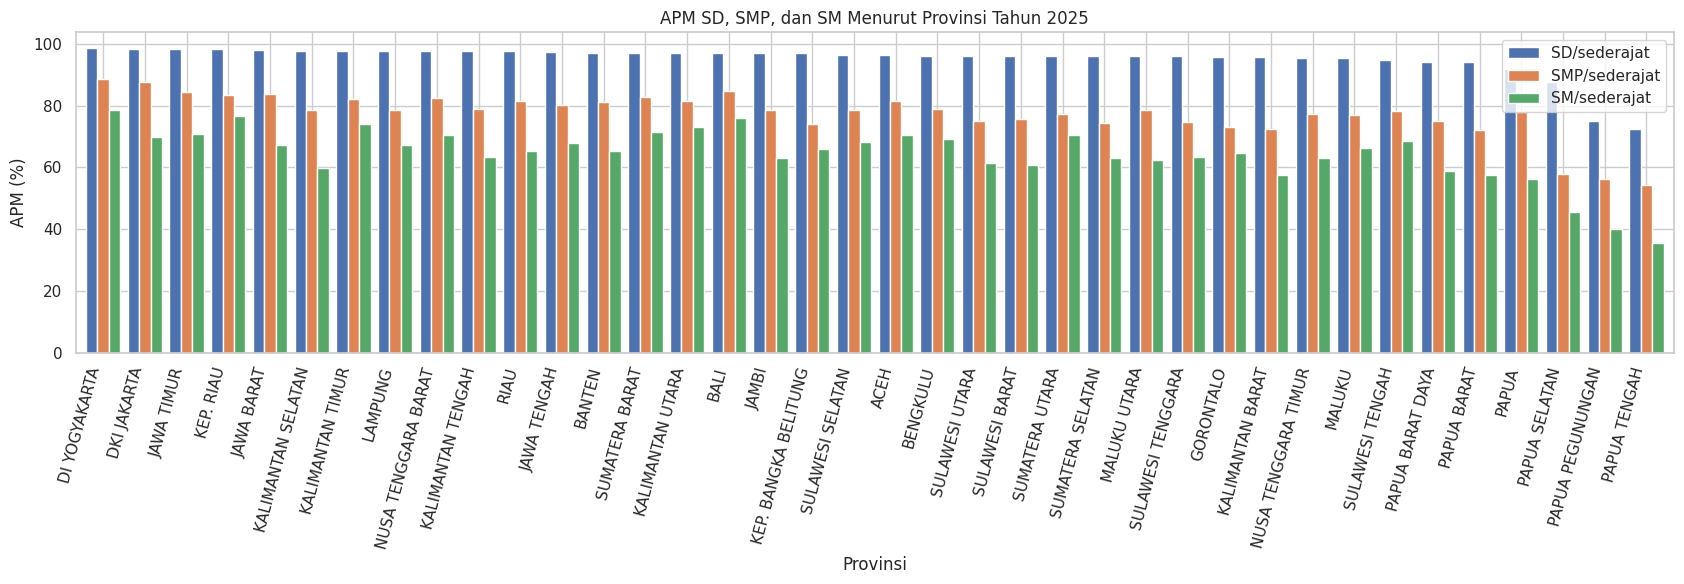

In [ ]:
# Perbandingan nilai APM per provinsi
df_plot = df.sort_values("APM_SD", ascending=False)
ax = df_plot.set_index("Provinsi")[fitur_apm].plot(
    kind="bar", figsize=(17, 6), width=0.82
)
ax.set_title("APM SD, SMP, dan SM Menurut Provinsi Tahun 2025")
ax.set_xlabel("Provinsi")
ax.set_ylabel("APM (%)")
plt.xticks(rotation=75, ha="right")
plt.legend(["SD/sederajat", "SMP/sederajat", "SM/sederajat"])
plt.tight_layout()
plt.show()

## 6. Korelasi Pearson antarvariabel

,APM_SD,APM_SMP,APM_SM
APM_SD,1.000,0.871,0.856
APM_SMP,0.871,1.000,0.918
APM_SM,0.856,0.918,1.000


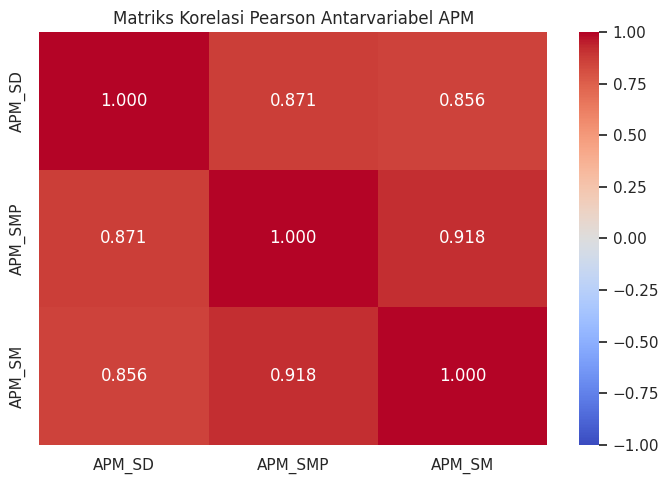

In [ ]:
korelasi = df[fitur_apm].corr(method="pearson")
display(korelasi.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(korelasi, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)
plt.title("Matriks Korelasi Pearson Antarvariabel APM")
plt.tight_layout()
plt.show()

## 7. Standardisasi data

In [ ]:
# K-Means menggunakan jarak; standardisasi membuat skala ketiga variabel sebanding.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[fitur_apm])

df_scaled = pd.DataFrame(X_scaled, columns=fitur_apm)
print("Rata-rata hasil standardisasi (mendekati 0):")
display(df_scaled.mean().to_frame("Mean").round(4))
print("Standar deviasi hasil standardisasi (ddof=0 mendekati 1):")
display(df_scaled.std(ddof=0).to_frame("Std").round(4))

Rata-rata hasil standardisasi (mendekati 0):


,Mean
APM_SD,0.0
APM_SMP,0.0
APM_SM,-0.0


Standar deviasi hasil standardisasi (ddof=0 mendekati 1):


,Std
APM_SD,1.0
APM_SMP,1.0
APM_SM,1.0


## 8. Evaluasi jumlah cluster K=2 sampai K=10

Tiga metrik dipakai bersama:
- **Silhouette Score:** semakin tinggi semakin baik.
- **Davies-Bouldin Index (DBI):** semakin rendah semakin baik.
- **Calinski-Harabasz Index (CHI):** semakin tinggi semakin baik.

Elbow/Inertia juga ditampilkan, tetapi tidak digunakan sendirian untuk menetapkan K. Evaluasi K=2 tetap ditampilkan walaupun target penelitian mengharuskan model akhir minimal 4 cluster.

In [ ]:
K_MIN = 2
K_MAX = 10
rentang_k = range(K_MIN, K_MAX + 1)

hasil_evaluasi = []
model_kandidat = {}

for k in rentang_k:
    model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=50
    )
    labels = model.fit_predict(X_scaled)
    model_kandidat[k] = (model, labels)

    hasil_evaluasi.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies_Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Ukuran_Cluster": sorted(pd.Series(labels).value_counts().tolist())
    })

evaluasi_k = pd.DataFrame(hasil_evaluasi)
display(evaluasi_k.round(4))

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Ukuran_Cluster
0,2,31.7354,0.7832,0.3662,93.3193,"[3, 35]"
1,3,16.3680,0.4587,0.6197,104.3842,"[3, 16, 19]"
2,4,11.3730,0.4561,0.4471,102.2689,"[1, 2, 16, 19]"
3,5,7.6076,0.3605,0.6100,115.3759,"[1, 2, 11, 11, 13]"
4,6,5.9100,0.3435,0.6602,117.0511,"[1, 2, 4, 9, 10, 12]"
5,7,4.7659,0.3453,0.7037,118.4209,"[1, 2, 3, 4, 8, 9, 11]"
6,8,3.8336,0.3685,0.6636,123.1602,"[1, 2, 3, 4, 6, 7, 7, 8]"
7,9,3.2267,0.3670,0.6554,124.4454,"[1, 2, 3, 3, 4, 5, 6, 7, 7]"
8,10,2.6665,0.3687,0.5934,129.8967,"[1, 1, 2, 3, 3, 3, 5, 6, 7, 7]"


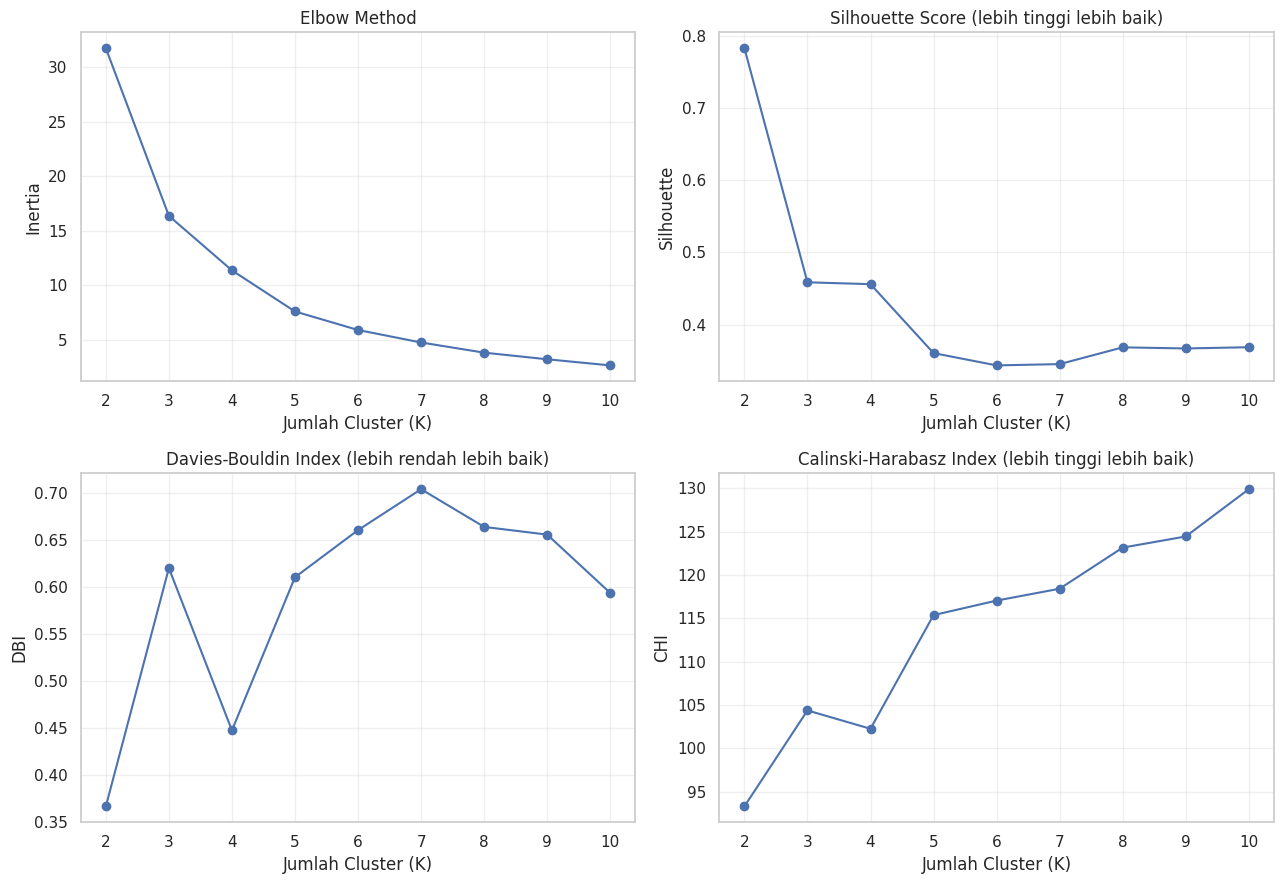

In [ ]:
# Grafik evaluasi
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(evaluasi_k["K"], evaluasi_k["Inertia"], marker="o")
axes[0, 0].set_title("Elbow Method")
axes[0, 0].set_xlabel("Jumlah Cluster (K)")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(evaluasi_k["K"], evaluasi_k["Silhouette"], marker="o")
axes[0, 1].set_title("Silhouette Score (lebih tinggi lebih baik)")
axes[0, 1].set_xlabel("Jumlah Cluster (K)")
axes[0, 1].set_ylabel("Silhouette")

axes[1, 0].plot(evaluasi_k["K"], evaluasi_k["Davies_Bouldin"], marker="o")
axes[1, 0].set_title("Davies-Bouldin Index (lebih rendah lebih baik)")
axes[1, 0].set_xlabel("Jumlah Cluster (K)")
axes[1, 0].set_ylabel("DBI")

axes[1, 1].plot(evaluasi_k["K"], evaluasi_k["Calinski_Harabasz"], marker="o")
axes[1, 1].set_title("Calinski-Harabasz Index (lebih tinggi lebih baik)")
axes[1, 1].set_xlabel("Jumlah Cluster (K)")
axes[1, 1].set_ylabel("CHI")

for ax in axes.flat:
    ax.set_xticks(list(rentang_k))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Menentukan model akhir dengan batas minimal 4 cluster

Sesuai keputusan desain penelitian, kandidat model akhir dibatasi pada **K=4 sampai K=10**. K dipilih dengan Silhouette Score tertinggi di antara kandidat tersebut, lalu DBI dan ukuran cluster diperiksa sebagai evaluasi pendamping.

Pemilihan ini **bukan berarti K terpilih merupakan optimum global**. Jika K=2 memiliki kualitas lebih tinggi, hal itu tetap harus dijelaskan dalam laporan sebagai temuan evaluasi. Jangan menghapus provinsi atau mengubah nilai APM hanya untuk memperbaiki skor.

**Catatan interpretasi hasil dataset ini:** K=4 menghasilkan ukuran cluster 19, 16, 1, dan 2. Karena ada cluster beranggota satu dan dua provinsi, K=4 memenuhi target jumlah kelompok tetapi belum menghasilkan segmentasi yang seimbang. Hal ini wajib dilaporkan sebagai keterbatasan hasil, bukan disembunyikan.


In [ ]:
K_MIN_PENELITIAN = 4
K_MAX_PENELITIAN = 10

kandidat = evaluasi_k[
    evaluasi_k["K"].between(K_MIN_PENELITIAN, K_MAX_PENELITIAN)
].copy()

# Aturan keputusan yang transparan: Silhouette tertinggi di antara K>=4.
# Jika terjadi nilai sama, DBI yang lebih rendah menjadi pemecah seri.
k_terpilih = (
    kandidat.sort_values(
        ["Silhouette", "Davies_Bouldin", "K"],
        ascending=[False, True, True]
    ).iloc[0]["K"]
)
K_FINAL = int(k_terpilih)

print("K terpilih dalam batas minimal 4:", K_FINAL)
print("\nPerbandingan kandidat K>=4:")
display(kandidat.sort_values("K").round(4))

K terpilih dalam batas minimal 4: 4

Perbandingan kandidat K>=4:


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Ukuran_Cluster
2,4,11.3730,0.4561,0.4471,102.2689,"[1, 2, 16, 19]"
3,5,7.6076,0.3605,0.6100,115.3759,"[1, 2, 11, 11, 13]"
4,6,5.9100,0.3435,0.6602,117.0511,"[1, 2, 4, 9, 10, 12]"
5,7,4.7659,0.3453,0.7037,118.4209,"[1, 2, 3, 4, 8, 9, 11]"
6,8,3.8336,0.3685,0.6636,123.1602,"[1, 2, 3, 4, 6, 7, 7, 8]"
7,9,3.2267,0.3670,0.6554,124.4454,"[1, 2, 3, 3, 4, 5, 6, 7, 7]"
8,10,2.6665,0.3687,0.5934,129.8967,"[1, 1, 2, 3, 3, 3, 5, 6, 7, 7]"


## 10. Menjalankan K-Means final

In [ ]:
kmeans_final = KMeans(
    n_clusters=K_FINAL,
    random_state=SEED,
    n_init=50
)
labels_raw = kmeans_final.fit_predict(X_scaled)

df_hasil = df.copy()
df_hasil["Cluster_Asli"] = labels_raw + 1

print("Jumlah cluster model final:", df_hasil["Cluster_Asli"].nunique())
print("\nJumlah anggota setiap cluster:")
display(
    df_hasil["Cluster_Asli"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Provinsi")
    .to_frame()
)

Jumlah cluster model final: 4

Jumlah anggota setiap cluster:


,Jumlah Provinsi
Cluster_Asli,
1,19
2,2
3,16
4,1


## 11. Menata nomor cluster dan memberi interpretasi

Nomor cluster asli dari K-Means bersifat arbitrer. Agar mudah dibaca, nomor cluster disusun ulang berdasarkan rata-rata gabungan tiga APM: cluster dengan rata-rata tertinggi menjadi Cluster 1, berikutnya Cluster 2, dan seterusnya. Penamaan ini hanya label deskriptif, bukan kategori resmi pemerintah.

In [ ]:
profil_awal = df_hasil.groupby("Cluster_Asli")[fitur_apm].mean()
profil_awal["Rata_Rata_Gabungan"] = profil_awal[fitur_apm].mean(axis=1)

urutan_cluster = (
    profil_awal["Rata_Rata_Gabungan"]
    .sort_values(ascending=False)
    .index.tolist()
)
pemetaan_cluster = {
    cluster_asli: i + 1
    for i, cluster_asli in enumerate(urutan_cluster)
}

df_hasil["Cluster"] = df_hasil["Cluster_Asli"].map(pemetaan_cluster)

# Label disusun menurut rata-rata gabungan APM, bukan nomor asli K-Means.
# Untuk K=4, gunakan deskripsi berurutan dan tandai kelompok sangat kecil.
if K_FINAL == 4:
    nama_cluster = {
        1: "APM Relatif Tertinggi",
        2: "APM Relatif Menengah Atas",
        3: "APM Relatif Menengah Bawah (Kelompok Khusus)",
        4: "APM Relatif Terendah"
    }
else:
    nama_cluster = {
        i: f"Cluster {i} (urutan rata-rata APM ke-{i})"
        for i in range(1, K_FINAL + 1)
    }

df_hasil["Kategori_Cluster"] = df_hasil["Cluster"].map(nama_cluster)
urutan_kategori = [nama_cluster[i] for i in range(1, K_FINAL + 1)]
df_hasil["Kategori_Cluster"] = pd.Categorical(
    df_hasil["Kategori_Cluster"],
    categories=urutan_kategori,
    ordered=True
)

print("Pemetaan label cluster asli ke nomor berurutan:", pemetaan_cluster)
display(
    df_hasil[["Provinsi"] + fitur_apm + ["Cluster", "Kategori_Cluster"]]
    .sort_values(["Cluster", "Provinsi"])
    .reset_index(drop=True)
)

Pemetaan label cluster asli ke nomor berurutan: {1: 1, 3: 2, 4: 3, 2: 4}


,Provinsi,APM_SD,APM_SMP,APM_SM,Cluster,Kategori_Cluster
0,ACEH,96.32,81.37,70.36,1,APM Relatif Tertinggi
1,BALI,97.05,84.81,76.06,1,APM Relatif Tertinggi
2,BANTEN,97.09,81.28,65.28,1,APM Relatif Tertinggi
3,BENGKULU,96.12,78.83,69.32,1,APM Relatif Tertinggi
4,DI YOGYAKARTA,98.77,88.67,78.42,1,APM Relatif Tertinggi
5,DKI JAKARTA,98.47,87.55,69.90,1,APM Relatif Tertinggi
6,JAWA BARAT,98.02,83.84,67.33,1,APM Relatif Tertinggi
7,JAWA TENGAH,97.21,80.29,67.81,1,APM Relatif Tertinggi
8,JAWA TIMUR,98.22,84.49,70.64,1,APM Relatif Tertinggi
9,KALIMANTAN TIMUR,97.68,82.01,73.96,1,APM Relatif Tertinggi


## 12. Profil dan komposisi cluster

In [ ]:
profil_cluster = df_hasil.groupby("Cluster")[fitur_apm].agg(["mean", "min", "max"])
display(profil_cluster.round(2))

rekap_cluster = (
    df_hasil.groupby(["Cluster", "Kategori_Cluster"])
    .agg(
        Jumlah_Provinsi=("Provinsi", "count"),
        APM_SD=("APM_SD", "mean"),
        APM_SMP=("APM_SMP", "mean"),
        APM_SM=("APM_SM", "mean")
    )
    .reset_index()
)
rekap_cluster["Persentase"] = (
    rekap_cluster["Jumlah_Provinsi"] / len(df_hasil) * 100
)
display(rekap_cluster.round(2))

# Daftar anggota setiap cluster
for cluster in sorted(df_hasil["Cluster"].unique()):
    print(f"\nCLUSTER {cluster} - {nama_cluster[cluster]}")
    display(
        df_hasil.loc[df_hasil["Cluster"] == cluster,
                     ["Provinsi"] + fitur_apm]
        .sort_values("APM_SM", ascending=False)
        .reset_index(drop=True)
    )

APM_SD               APM_SMP               APM_SM              
          mean    min    max    mean    min    max   mean    min    max
Cluster                                                                
1        97.22  94.67  98.77   81.97  77.41  88.67  70.55  65.22  78.42
2        95.70  91.81  97.79   75.83  72.24  78.91  61.68  56.13  66.29
3        87.64  87.64  87.64   57.72  57.72  57.72  45.48  45.48  45.48
4        73.70  72.55  74.85   55.24  54.33  56.16  37.73  35.59  39.87

,Cluster,Kategori_Cluster,Jumlah_Provinsi,APM_SD,APM_SMP,APM_SM,Persentase
0,1,APM Relatif Tertinggi,19,97.22,81.97,70.55,50.00
1,1,APM Relatif Menengah Atas,0,NaN,NaN,NaN,0.00
2,1,APM Relatif Menengah Bawah (Kelompok Khusus),0,NaN,NaN,NaN,0.00
3,1,APM Relatif Terendah,0,NaN,NaN,NaN,0.00
4,2,APM Relatif Tertinggi,0,NaN,NaN,NaN,0.00
5,2,APM Relatif Menengah Atas,16,95.70,75.83,61.68,42.11
6,2,APM Relatif Menengah Bawah (Kelompok Khusus),0,NaN,NaN,NaN,0.00
7,2,APM Relatif Terendah,0,NaN,NaN,NaN,0.00
8,3,APM Relatif Tertinggi,0,NaN,NaN,NaN,0.00
9,3,APM Relatif Menengah Atas,0,NaN,NaN,NaN,0.00



CLUSTER 1 - APM Relatif Tertinggi


,Provinsi,APM_SD,APM_SMP,APM_SM
0,DI YOGYAKARTA,98.77,88.67,78.42
1,KEP. RIAU,98.20,83.55,76.54
2,BALI,97.05,84.81,76.06
3,KALIMANTAN TIMUR,97.68,82.01,73.96
4,KALIMANTAN UTARA,97.05,81.49,73.13
5,SUMATERA BARAT,97.06,82.70,71.57
6,JAWA TIMUR,98.22,84.49,70.64
7,NUSA TENGGARA BARAT,97.62,82.54,70.43
8,SUMATERA UTARA,95.99,77.41,70.40
9,ACEH,96.32,81.37,70.36



CLUSTER 2 - APM Relatif Menengah Atas


,Provinsi,APM_SD,APM_SMP,APM_SM
0,MALUKU,95.29,77.02,66.29
1,KEP. BANGKA BELITUNG,97.00,74.06,65.94
2,GORONTALO,95.75,72.95,64.63
3,KALIMANTAN TENGAH,97.55,78.91,63.31
4,SULAWESI TENGGARA,95.89,74.78,63.31
5,SUMATERA SELATAN,95.98,74.27,63.08
6,JAMBI,97.02,78.47,63.05
7,NUSA TENGGARA TIMUR,95.45,77.28,62.88
8,MALUKU UTARA,95.90,78.65,62.32
9,SULAWESI UTARA,96.00,75.05,61.26



CLUSTER 3 - APM Relatif Menengah Bawah (Kelompok Khusus)


,Provinsi,APM_SD,APM_SMP,APM_SM
0,PAPUA SELATAN,87.64,57.72,45.48



CLUSTER 4 - APM Relatif Terendah


,Provinsi,APM_SD,APM_SMP,APM_SM
0,PAPUA PEGUNUNGAN,74.85,56.16,39.87
1,PAPUA TENGAH,72.55,54.33,35.59


In [ ]:
# Tandai cluster kecil, khususnya cluster dengan satu anggota.
ukuran_cluster = df_hasil["Cluster"].value_counts().sort_index()
cluster_kecil = ukuran_cluster[ukuran_cluster < 3]

print("Pemeriksaan ukuran cluster:")
display(ukuran_cluster.rename("Jumlah Provinsi").to_frame())

if len(cluster_kecil) > 0:
    print(
        "PERHATIAN: terdapat cluster dengan kurang dari 3 provinsi. "
        "Interpretasikan sebagai kelompok sangat kecil/khusus; "
        "jangan menyatakan seluruh cluster memiliki ukuran seimbang."
    )
    display(
        df_hasil[df_hasil["Cluster"].isin(cluster_kecil.index)]
        [["Provinsi"] + fitur_apm + ["Cluster", "Kategori_Cluster"]]
        .sort_values("Cluster")
    )
else:
    print("Semua cluster memiliki minimal 3 provinsi.")

Pemeriksaan ukuran cluster:


,Jumlah Provinsi
Cluster,
1,19
2,16
3,1
4,2


PERHATIAN: terdapat cluster dengan kurang dari 3 provinsi. Interpretasikan sebagai kelompok sangat kecil/khusus; jangan menyatakan seluruh cluster memiliki ukuran seimbang.


,Provinsi,APM_SD,APM_SMP,APM_SM,Cluster,Kategori_Cluster
35,PAPUA SELATAN,87.64,57.72,45.48,3,APM Relatif Menengah Bawah (Kelompok Khusus)
36,PAPUA TENGAH,72.55,54.33,35.59,4,APM Relatif Terendah
37,PAPUA PEGUNUNGAN,74.85,56.16,39.87,4,APM Relatif Terendah


## 13. Visualisasi profil rata-rata cluster

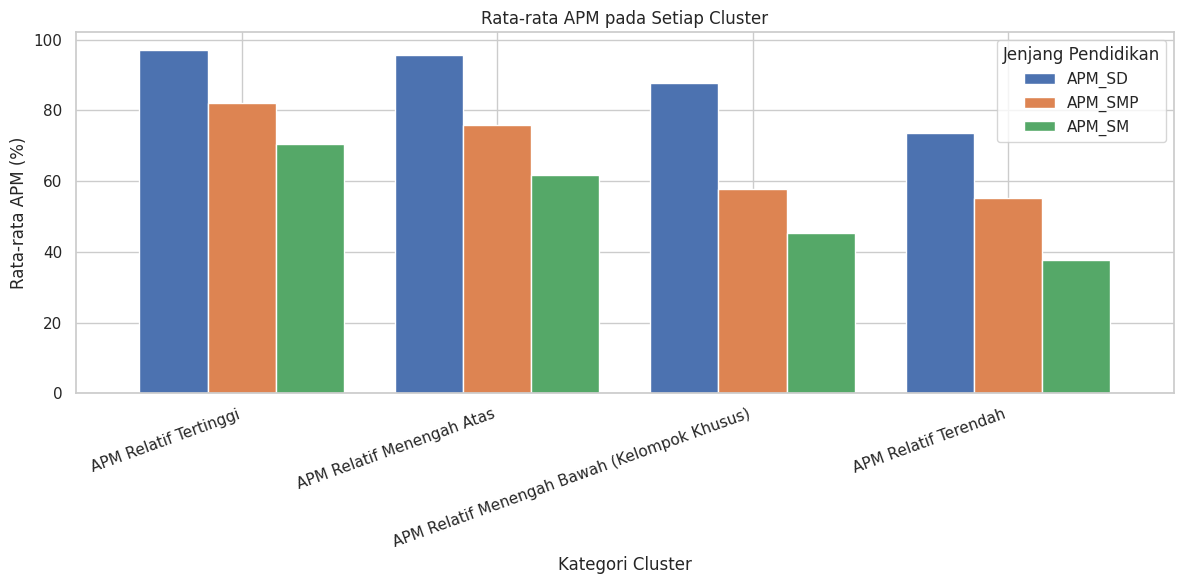

In [ ]:
profil_mean = df_hasil.groupby("Cluster", observed=True)[fitur_apm].mean()
profil_mean.index = [nama_cluster[i] for i in profil_mean.index]

ax = profil_mean.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Rata-rata APM pada Setiap Cluster")
ax.set_xlabel("Kategori Cluster")
ax.set_ylabel("Rata-rata APM (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Jenjang Pendidikan")
plt.tight_layout()
plt.show()

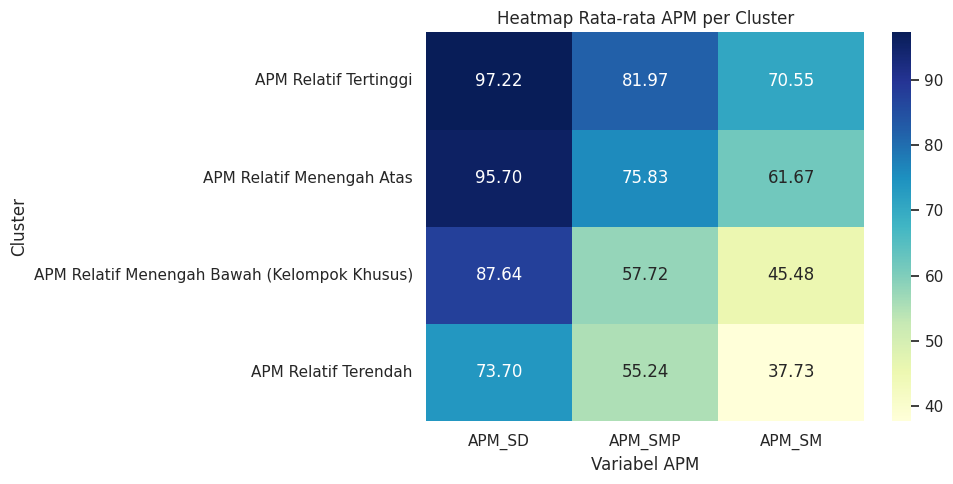

In [ ]:
profil_heatmap = df_hasil.groupby("Cluster", observed=True)[fitur_apm].mean()
profil_heatmap.index = [nama_cluster[i] for i in profil_heatmap.index]

plt.figure(figsize=(10, 5))
sns.heatmap(
    profil_heatmap,
    annot=True, fmt=".2f", cmap="YlGnBu"
)
plt.title("Heatmap Rata-rata APM per Cluster")
plt.xlabel("Variabel APM")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## 14. Visualisasi PCA (dua dimensi)

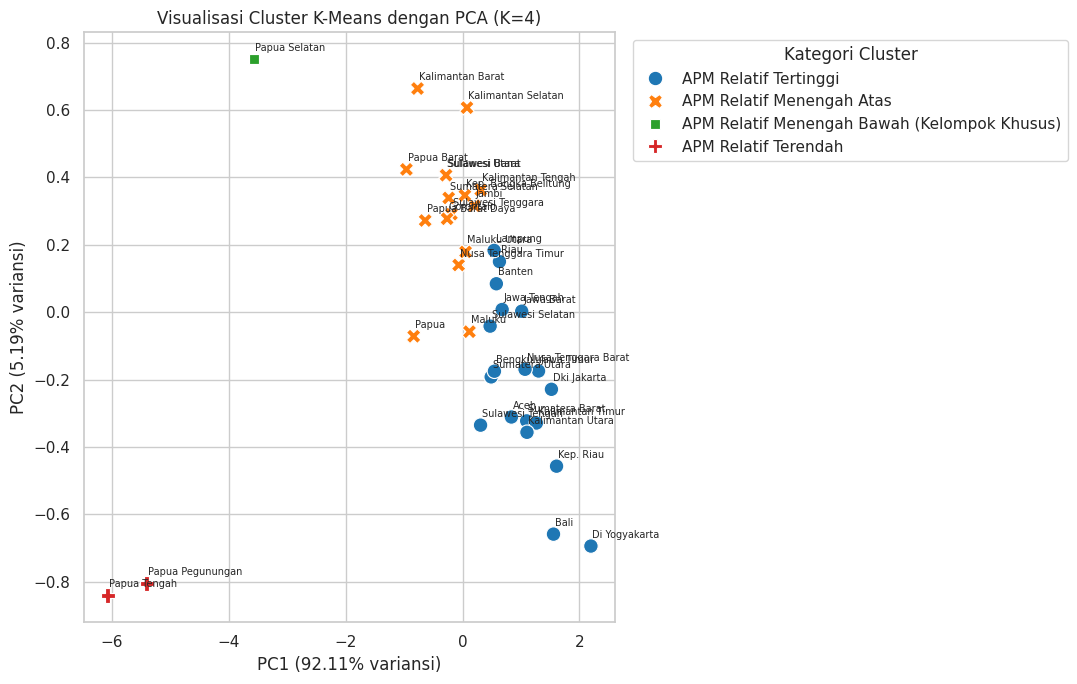

Variansi dijelaskan PC1 dan PC2: 97.3 %


In [ ]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

df_hasil["PCA1"] = X_pca[:, 0]
df_hasil["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_hasil,
    x="PCA1", y="PCA2",
    hue="Kategori_Cluster",
    style="Kategori_Cluster",
    s=110, palette="tab10"
)
for _, row in df_hasil.iterrows():
    plt.text(row["PCA1"] + 0.025, row["PCA2"] + 0.025,
             row["Provinsi"].title(), fontsize=7)
plt.title(f"Visualisasi Cluster K-Means dengan PCA (K={K_FINAL})")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variansi)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variansi)")
plt.legend(title="Kategori Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Variansi dijelaskan PC1 dan PC2:",
      round(pca.explained_variance_ratio_.sum()*100, 2), "%")

## 15. Evaluasi akhir model dan keterbatasan interpretasi

Silhouette, DBI, dan CH merupakan evaluasi internal struktur cluster. Nilai-nilai ini tidak membuktikan hubungan sebab-akibat atau kualitas pendidikan secara keseluruhan.

**ANOVA tidak digunakan sebagai bukti independen bahwa cluster berbeda**, karena cluster dibentuk menggunakan variabel APM yang sama dengan variabel yang akan dibandingkan. Pengujian ANOVA pada data yang sama akan bersifat sirkular dan cenderung menemukan perbedaan yang memang dibentuk oleh algoritma. Fokus interpretasi penelitian adalah profil deskriptif dan metrik internal clustering.

Untuk data ini, tiga variabel APM juga berkorelasi kuat. Karena itu, pengelompokan terutama mencerminkan tingkat partisipasi pendidikan secara umum. Cluster tunggal Papua Selatan pada K=4 harus diperlakukan sebagai kelompok khusus pada dataset, bukan generalisasi karakteristik provinsi lain.


In [ ]:
baris_final = evaluasi_k[evaluasi_k["K"] == K_FINAL].iloc[0]
baris_k2 = evaluasi_k[evaluasi_k["K"] == 2].iloc[0]

print("RINGKASAN MODEL FINAL")
print("---------------------")
print("Jumlah provinsi:", len(df_hasil))
print("Variabel:", ", ".join(fitur_apm))
print("K model final:", K_FINAL)
print("Silhouette final:", round(baris_final["Silhouette"], 4))
print("DBI final:", round(baris_final["Davies_Bouldin"], 4))
print("CHI final:", round(baris_final["Calinski_Harabasz"], 4))
print("Silhouette K=2 sebagai pembanding:", round(baris_k2["Silhouette"], 4))
print("Ukuran cluster:", df_hasil["Cluster"].value_counts().sort_index().to_dict())

RINGKASAN MODEL FINAL
---------------------
Jumlah provinsi: 38
Variabel: APM_SD, APM_SMP, APM_SM
K model final: 4
Silhouette final: 0.4561
DBI final: 0.4471
CHI final: 102.2689
Silhouette K=2 sebagai pembanding: 0.7832
Ukuran cluster: {1: 19, 2: 16, 3: 1, 4: 2}


## 16. Ekspor hasil untuk laporan dan dashboard

In [ ]:
# File hasil berisi identitas provinsi, variabel asli, nomor cluster,
# nama kategori, dan koordinat PCA.
kolom_ekspor = [
    "Provinsi", "APM_SD", "APM_SMP", "APM_SM",
    "Cluster", "Kategori_Cluster", "PCA1", "PCA2"
]
hasil_ekspor = df_hasil[kolom_ekspor].sort_values(["Cluster", "Provinsi"])
hasil_ekspor.to_csv("hasil_clustering_APM_2025.csv", index=False)

evaluasi_k.to_csv("evaluasi_jumlah_cluster_APM_2025.csv", index=False)
rekap_cluster.to_csv("profil_cluster_APM_2025.csv", index=False)

print("File berhasil disimpan:")
print("- hasil_clustering_APM_2025.csv")
print("- evaluasi_jumlah_cluster_APM_2025.csv")
print("- profil_cluster_APM_2025.csv")

# Unduh otomatis dari Google Colab
from google.colab import files
files.download("hasil_clustering_APM_2025.csv")
files.download("evaluasi_jumlah_cluster_APM_2025.csv")
files.download("profil_cluster_APM_2025.csv")

File berhasil disimpan:
- hasil_clustering_APM_2025.csv
- evaluasi_jumlah_cluster_APM_2025.csv
- profil_cluster_APM_2025.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Panduan pelaporan hasil

Saat menyusun laporan, laporkan:
1. Dataset terdiri atas 38 provinsi dan tiga variabel APM tahun 2025.
2. Baris agregat Indonesia tidak dimasukkan karena unit analisis penelitian adalah provinsi.
3. StandardScaler digunakan sebelum K-Means.
4. Evaluasi K=2 sampai K=10 ditampilkan secara transparan.
5. Model final dipilih dari K>=4 sesuai target segmentasi penelitian, dengan dasar metrik yang ditampilkan.
6. Jika terdapat cluster tunggal atau sangat kecil, jelaskan sebagai karakteristik hasil dan keterbatasan segmentasi.
7. Jangan menyatakan K final sebagai optimum global jika K=2 mempunyai skor evaluasi lebih baik.
8. Nama kategori cluster dibuat berdasarkan rata-rata tiga APM, bukan label resmi.

In [1]:
!jupyter nbconvert --to html PSD.ipynb --template basic

SyntaxError: invalid syntax (3984846565.py, line 1)